# Time-varying bifurcation data plots

This notebook loads a generated dataset and plots the main arrays in a compact way:

- raw full trajectories and drifting bifurcation parameter
- train/context/test window shapes
- selected windows with `phi` and `phi_raw`
- per-regime phase plots and parameter crossings

In [ ]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update(
    {
        "figure.figsize": (11, 4),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titlesize": 11,
        "axes.labelsize": 10,
        "legend.fontsize": 9,
    }
)

# Change this if you generated data somewhere else.
DATA_DIR = Path("generated_plot_test")  # ("generated_long_trajectories_constant")

with open(DATA_DIR / "metadata.json", "r", encoding="utf-8") as f:
    metadata = json.load(f)

dt = float(metadata.get("args", {}).get("dt", 1.0))
context_len = int(metadata.get("args", {}).get("context_len", 0))
prediction_len = int(metadata.get("args", {}).get("prediction_len", 0))

metadata["args"], metadata["shapes"]

({'output_dir': 'generated_plot_test',
  'n_steps': 8000,
  'dt': 0.01,
  'trajectories_per_regime': 1,
  'windows_per_trajectory': 2,
  'context_len': 200,
  'seq_len': 300,
  'prediction_len': 300,
  'seed': 8,
  'init_scale': 0.5,
  'rtol': 1e-06,
  'atol': 1e-08},
 {'trajectories': [15, 8000, 3],
  'trajectory_phi': [15, 8000, 1],
  'data': [200, 30, 3],
  'context': [200, 30, 3],
  'phi': [200, 30, 1],
  'test': [500, 15, 3],
  'test_phi': [500, 15, 1]})

In [7]:
arrays = {}
for name in [
    "trajectories",
    "trajectory_phi",
    "trajectory_phi_raw",
    "trajectory_regime_names",
    "trajectory_regime_index",
    "context",
    "data",
    "phi",
    "phi_raw",
    "context_phi",
    "context_phi_raw",
    "test",
    "test_phi",
    "test_phi_raw",
    "window_regime_names",
    "start_indices",
]:
    path = DATA_DIR / f"{name}.npy"
    if path.exists():
        arrays[name] = np.load(path, allow_pickle=True)

for name, value in arrays.items():
    print(f"{name:24s} {value.shape} {value.dtype}")

trajectories             (15, 8000, 3) float32
trajectory_phi           (15, 8000, 1) float32
trajectory_phi_raw       (15, 8000, 1) float32
trajectory_regime_names  (15,) <U28
trajectory_regime_index  (15,) int64
context                  (200, 30, 3) float32
data                     (200, 30, 3) float32
phi                      (200, 30, 1) float32
phi_raw                  (200, 30, 1) float32
context_phi              (200, 30, 1) float32
context_phi_raw          (200, 30, 1) float32
test                     (500, 15, 3) float32
test_phi                 (500, 15, 1) float32
test_phi_raw             (500, 15, 1) float32
window_regime_names      (30,) <U28
start_indices            (30,) int64


## Helpers

In [8]:
regime_names = arrays.get("trajectory_regime_names")
unique_regimes = (
    list(dict.fromkeys(regime_names.tolist())) if regime_names is not None else []
)


def time_axis(n):
    return np.arange(n) * dt


def indices_for_regime(regime_name):
    return np.flatnonzero(regime_names == regime_name)


def regime_info(regime_name):
    for item in metadata.get("regimes", []):
        if item["name"] == regime_name:
            return item
    return {
        "name": regime_name,
        "boundary": 0.0,
        "parameter": "parameter",
        "family": "unknown",
    }


def plot_full_trajectory(series_idx=0):
    x = arrays["trajectories"][series_idx]
    phi = arrays["trajectory_phi"][series_idx, :, 0]
    phi_raw = arrays["trajectory_phi_raw"][series_idx, :, 0]
    name = (
        str(regime_names[series_idx])
        if regime_names is not None
        else f"series {series_idx}"
    )
    info = regime_info(name)
    t = time_axis(x.shape[0])

    fig, axes = plt.subplots(5, 1, figsize=(11, 11), sharex=True)
    state_colors = ["tab:blue", "tab:green", "tab:red"]
    for dim, color in enumerate(state_colors):
        axes[dim].plot(t, x[:, dim], color=color, label=f"x{dim}")
        axes[dim].set_ylabel(f"x{dim}")
        axes[dim].legend(loc="best")
    axes[0].set_title(f"Full trajectory: {name}")

    axes[3].plot(t, phi, color="tab:purple")
    axes[3].axhline(0.0, color="black", lw=1, ls="--", label="bifurcation boundary")
    axes[3].set_ylabel("normalized phi")
    axes[3].legend()

    axes[4].plot(t, phi_raw, color="tab:orange")
    axes[4].axhline(
        info.get("boundary", 0.0), color="black", lw=1, ls="--", label="raw boundary"
    )
    axes[4].set_xlabel("time")
    axes[4].set_ylabel(info.get("parameter", "raw parameter"))
    axes[4].legend()
    fig.tight_layout()
    return fig


def plot_window(window_idx=0, split="train"):
    if split == "test":
        x = arrays["test"][:, window_idx, :]
        phi = arrays["test_phi"][:, window_idx, 0]
        phi_raw = arrays["test_phi_raw"][:, window_idx, 0]
        name = (
            str(regime_names[window_idx])
            if regime_names is not None
            else f"test {window_idx}"
        )
    else:
        x = arrays["data"][:, window_idx, :]
        phi = arrays["phi"][:, window_idx, 0]
        phi_raw = arrays["phi_raw"][:, window_idx, 0]
        window_names = arrays.get("window_regime_names")
        name = (
            str(window_names[window_idx])
            if window_names is not None
            else f"window {window_idx}"
        )

    t = time_axis(x.shape[0])
    fig, axes = plt.subplots(4, 1, figsize=(11, 9), sharex=True)
    state_colors = ["tab:blue", "tab:green", "tab:red"]
    for dim, color in enumerate(state_colors):
        axes[dim].plot(t, x[:, dim], color=color, label=f"x{dim}")
        axes[dim].set_ylabel(f"x{dim}")
        axes[dim].legend(loc="best")
    axes[0].set_title(f"{split} window {window_idx}: {name}")

    axes[3].plot(t, phi, label="phi", color="tab:purple")
    ax2 = axes[3].twinx()
    ax2.plot(t, phi_raw, label="phi_raw", color="tab:orange", alpha=0.75)
    axes[3].axhline(0.0, color="black", lw=1, ls="--")
    axes[3].set_ylabel("normalized phi")
    ax2.set_ylabel("raw parameter")
    lines, labels = axes[3].get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    axes[3].legend(lines + lines2, labels + labels2, loc="best")
    axes[3].set_xlabel("time")
    fig.tight_layout()
    return fig

## Dataset overview

In [9]:
print(metadata.get("description", ""))
print(metadata.get("phi_convention", ""))
print(f"Number of regimes: {len(unique_regimes)}")

for i, name in enumerate(unique_regimes):
    info = regime_info(name)
    print(
        f"{i:2d}  {name:32s} family={info.get('family')} parameter={info.get('parameter')} boundary={info.get('boundary')}"
    )

Time-varying bifurcation data with known normalized phi_t for DynaMix external input experiments.
phi arrays are normalized as (raw_parameter - bifurcation_boundary) / max(abs(start-boundary), abs(end-boundary)); boundary is therefore phi=0.
Number of regimes: 15
 0  lorenz_pitchfork_rho             family=Lorenz parameter=rho boundary=1.0
 1  lorenz_hopf_rho                  family=Lorenz parameter=rho boundary=24.736842105263154
 2  rossler_hopf_c                   family=Rossler parameter=c boundary=0.4
 3  chen_origin_c                    family=Chen parameter=c boundary=17.5
 4  lu_origin_c                      family=Lu parameter=c boundary=0.0
 5  brusselator_hopf_B               family=Brusselator3D parameter=B boundary=2.0
 6  vanderpol_hopf_mu                family=VanDerPol3D parameter=mu boundary=0.0
 7  normal_pitchfork_mu              family=PitchforkNormalForm3D parameter=mu boundary=0.0
 8  normal_saddle_node_mu            family=SaddleNodeNormalForm3D parameter=mu boun

## Plot one full trajectory

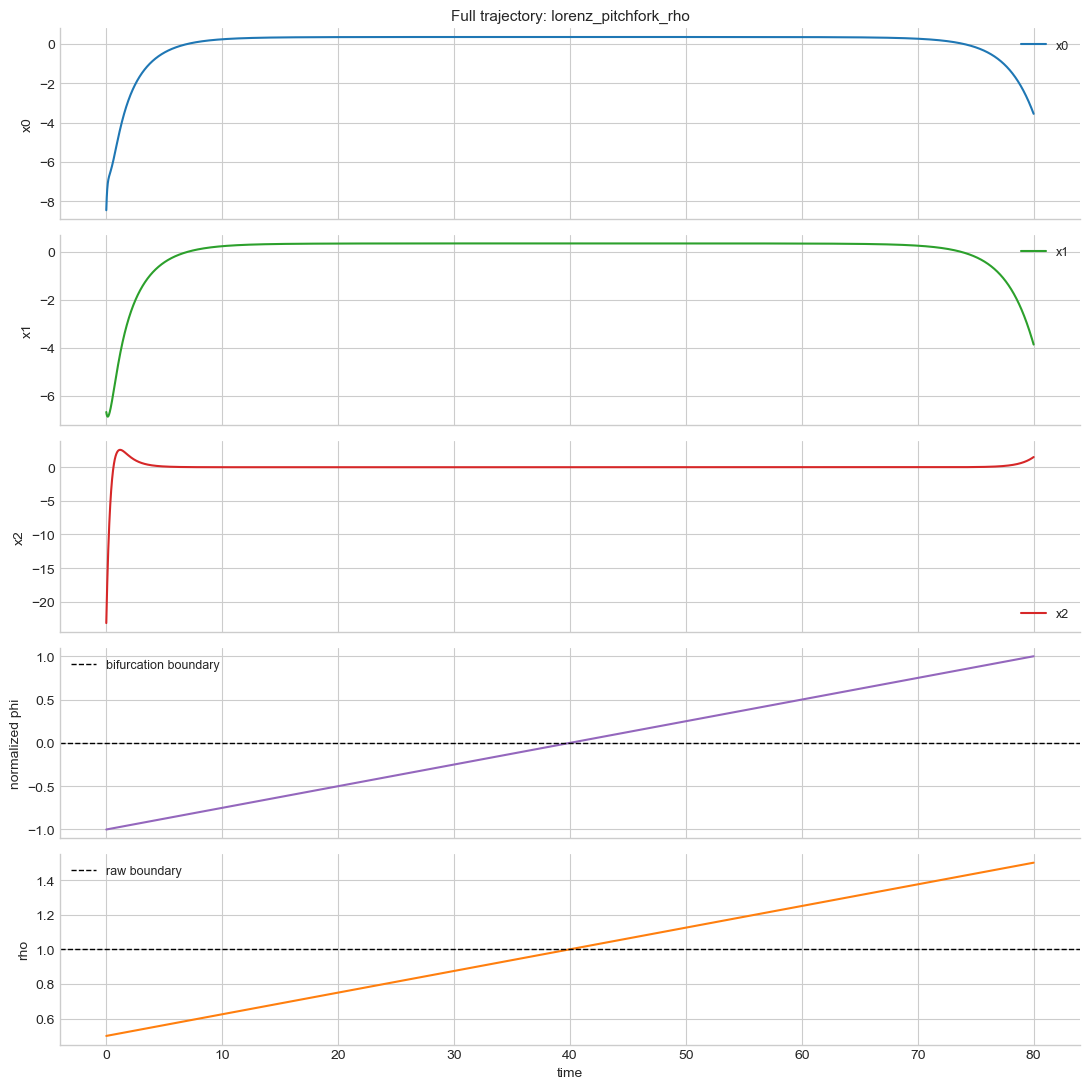

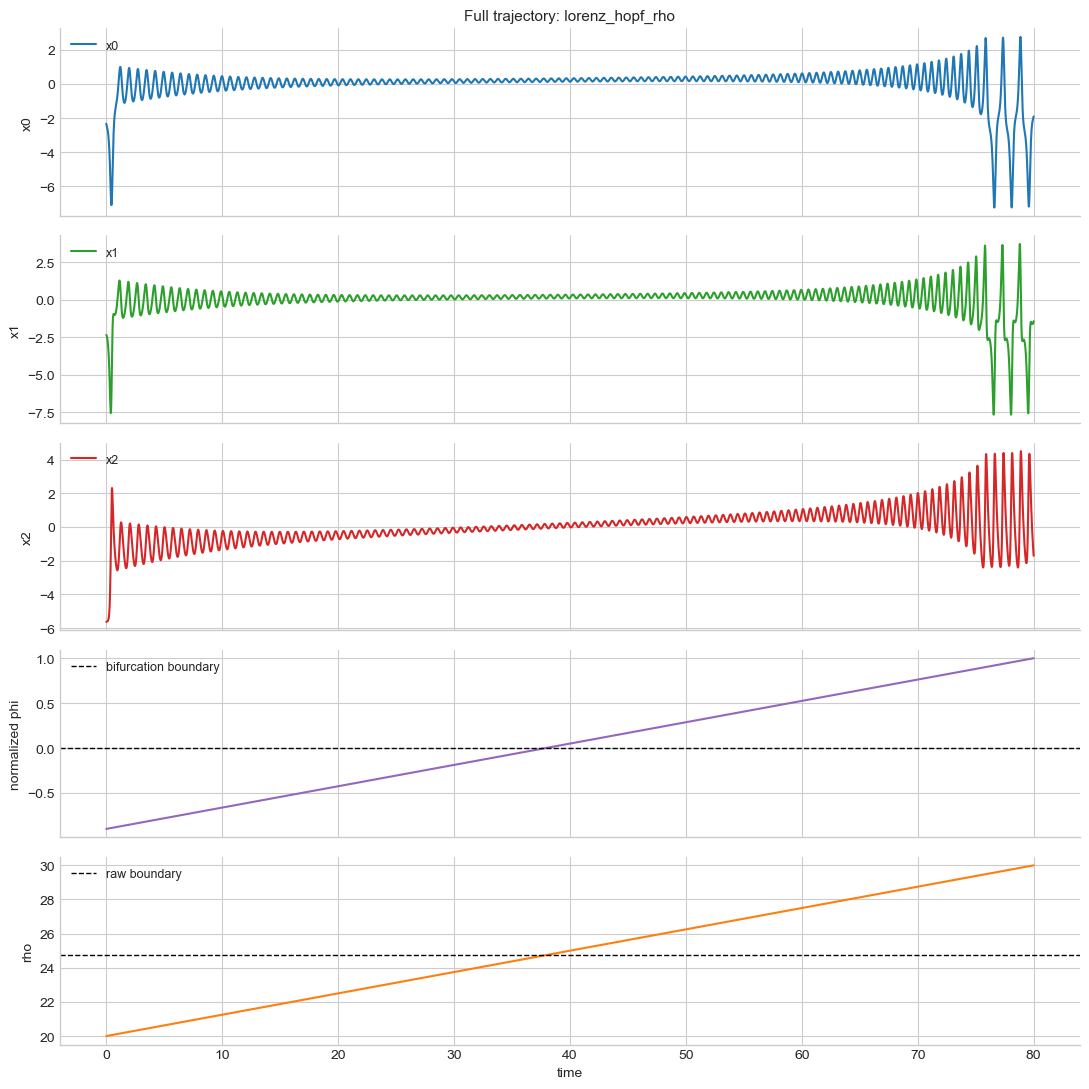

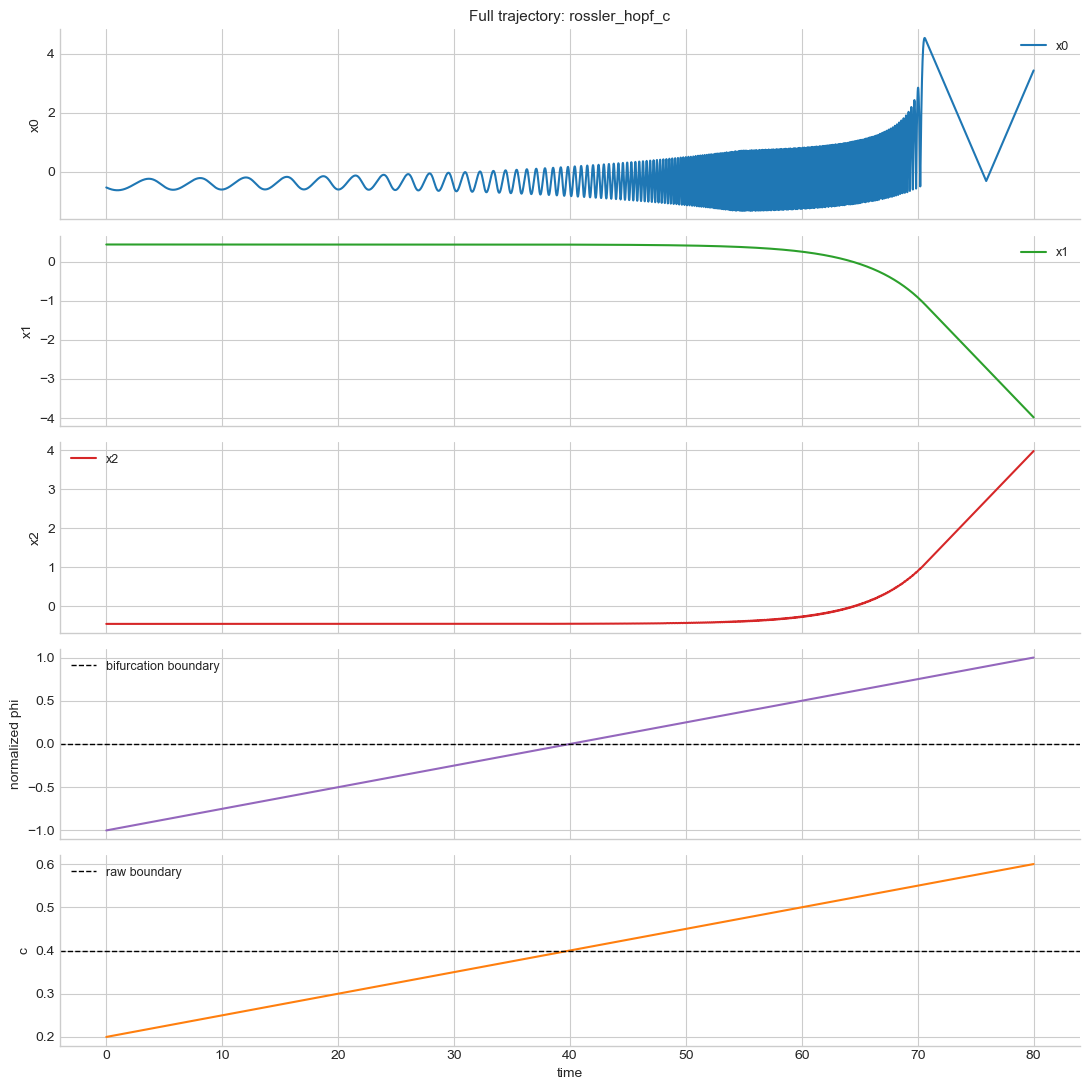

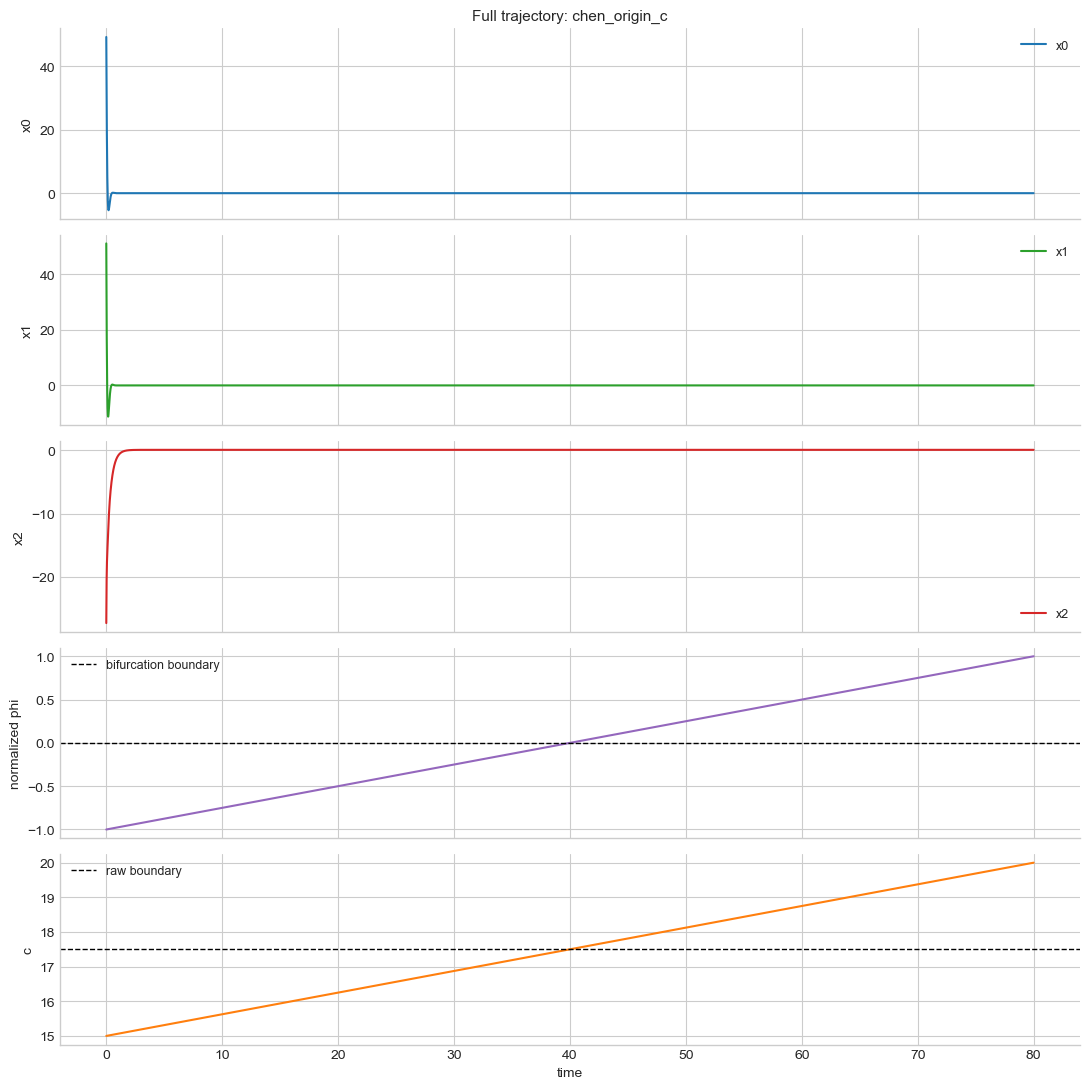

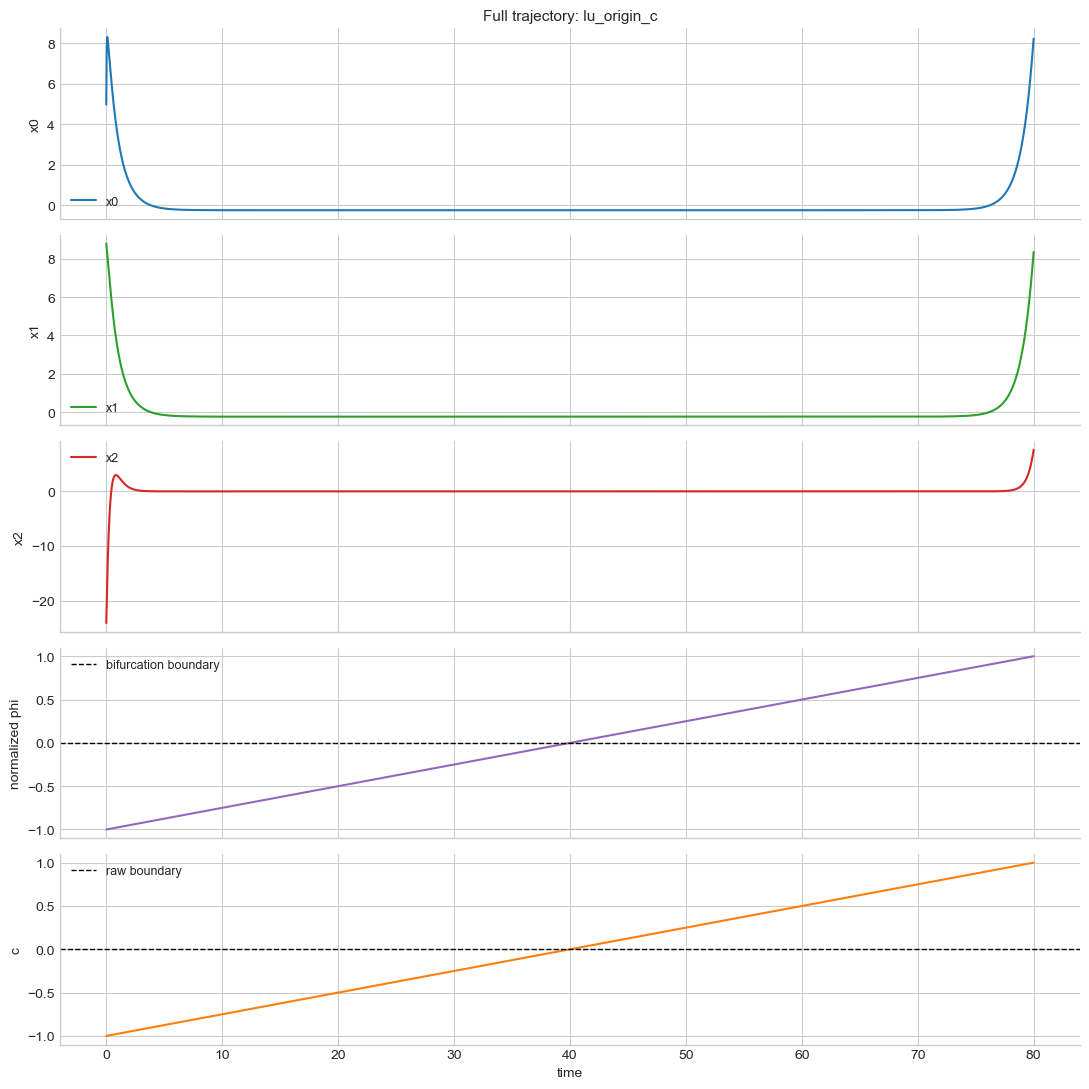

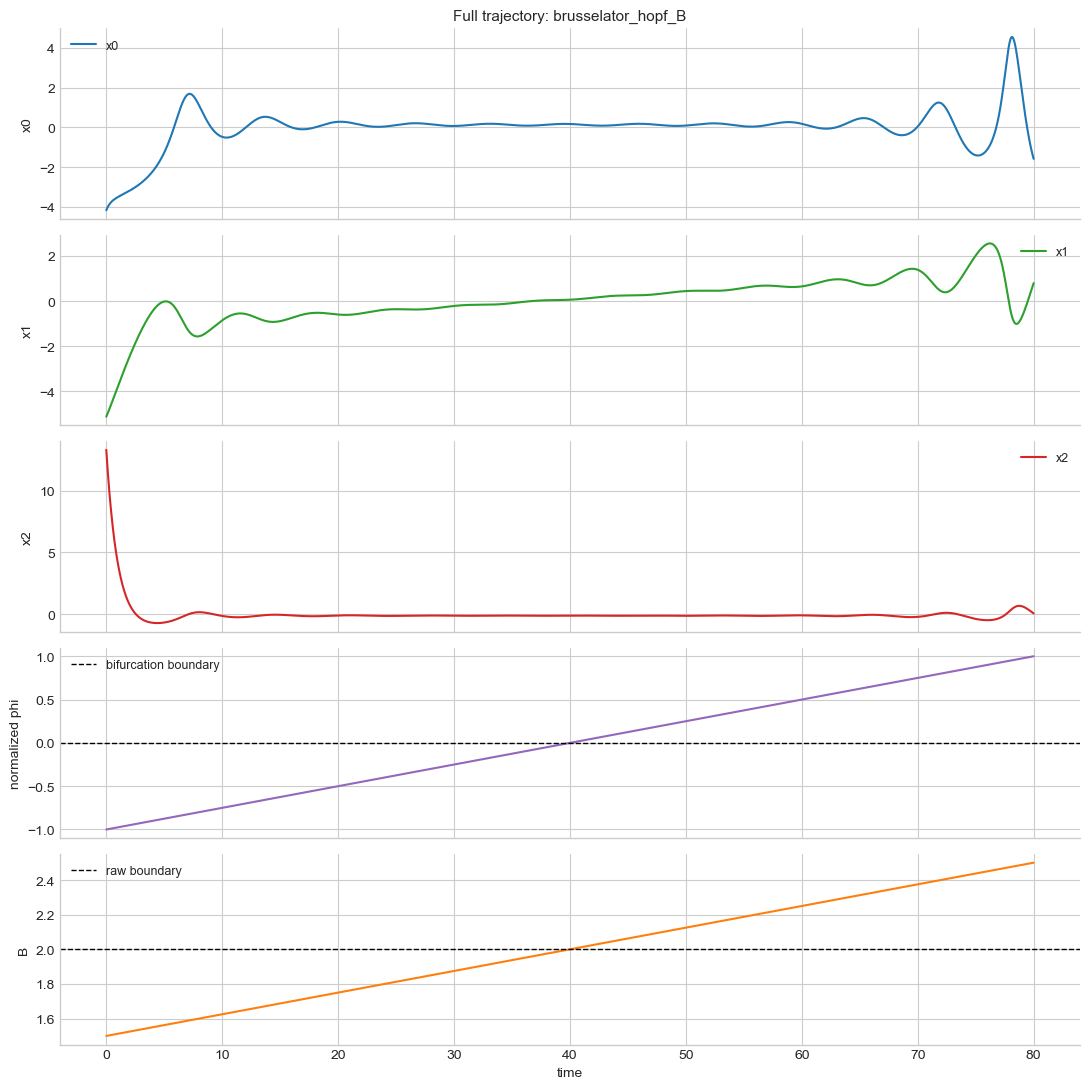

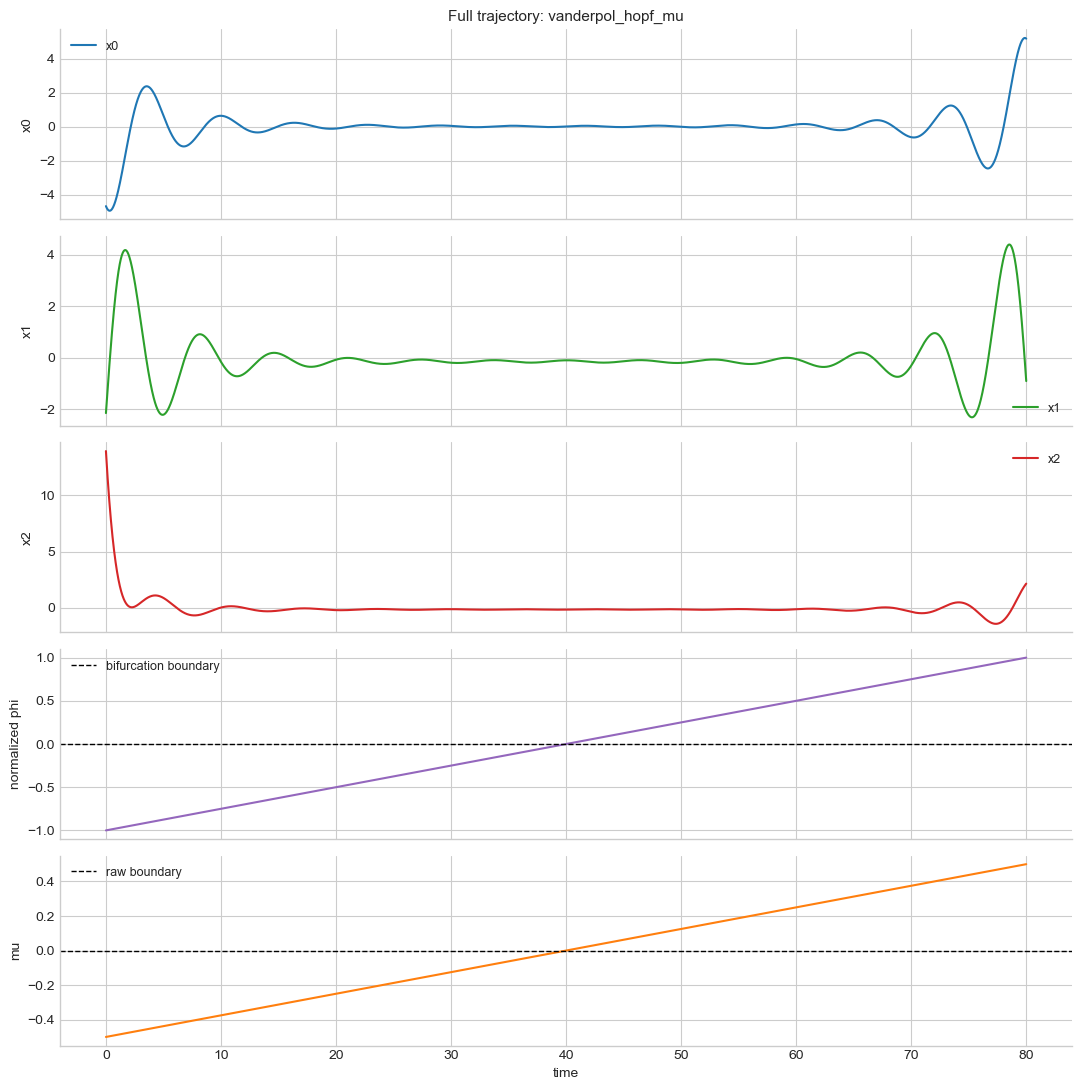

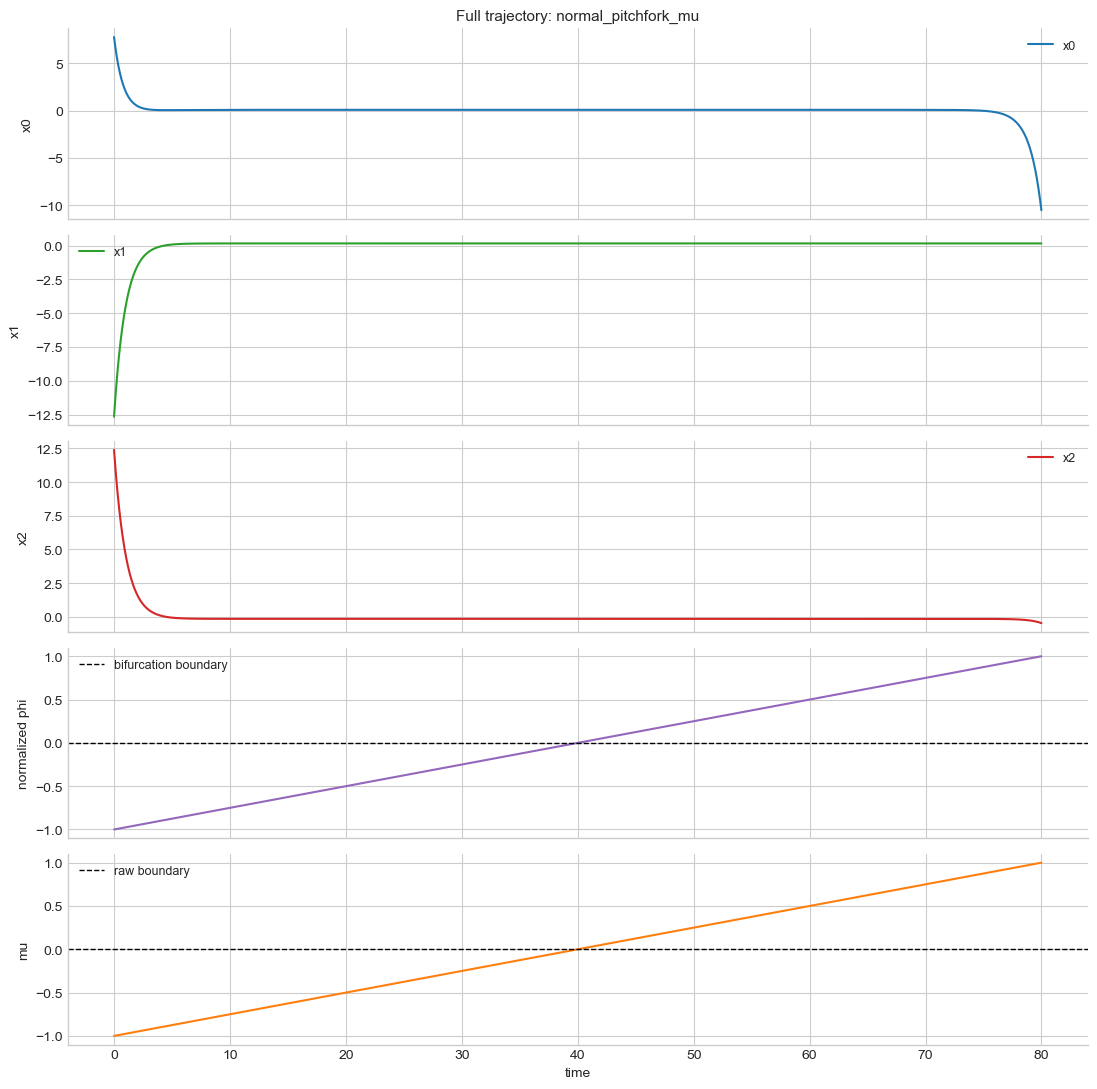

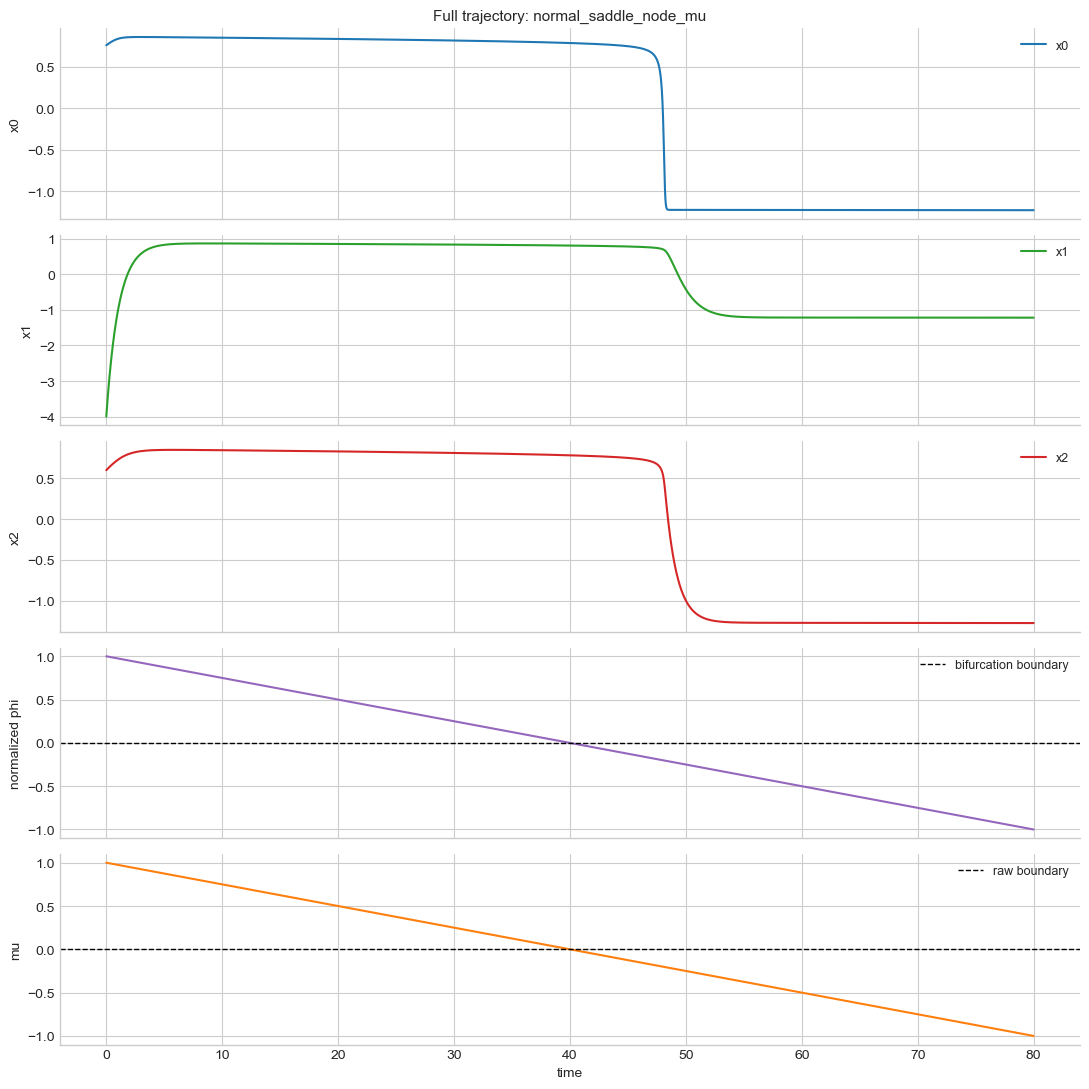

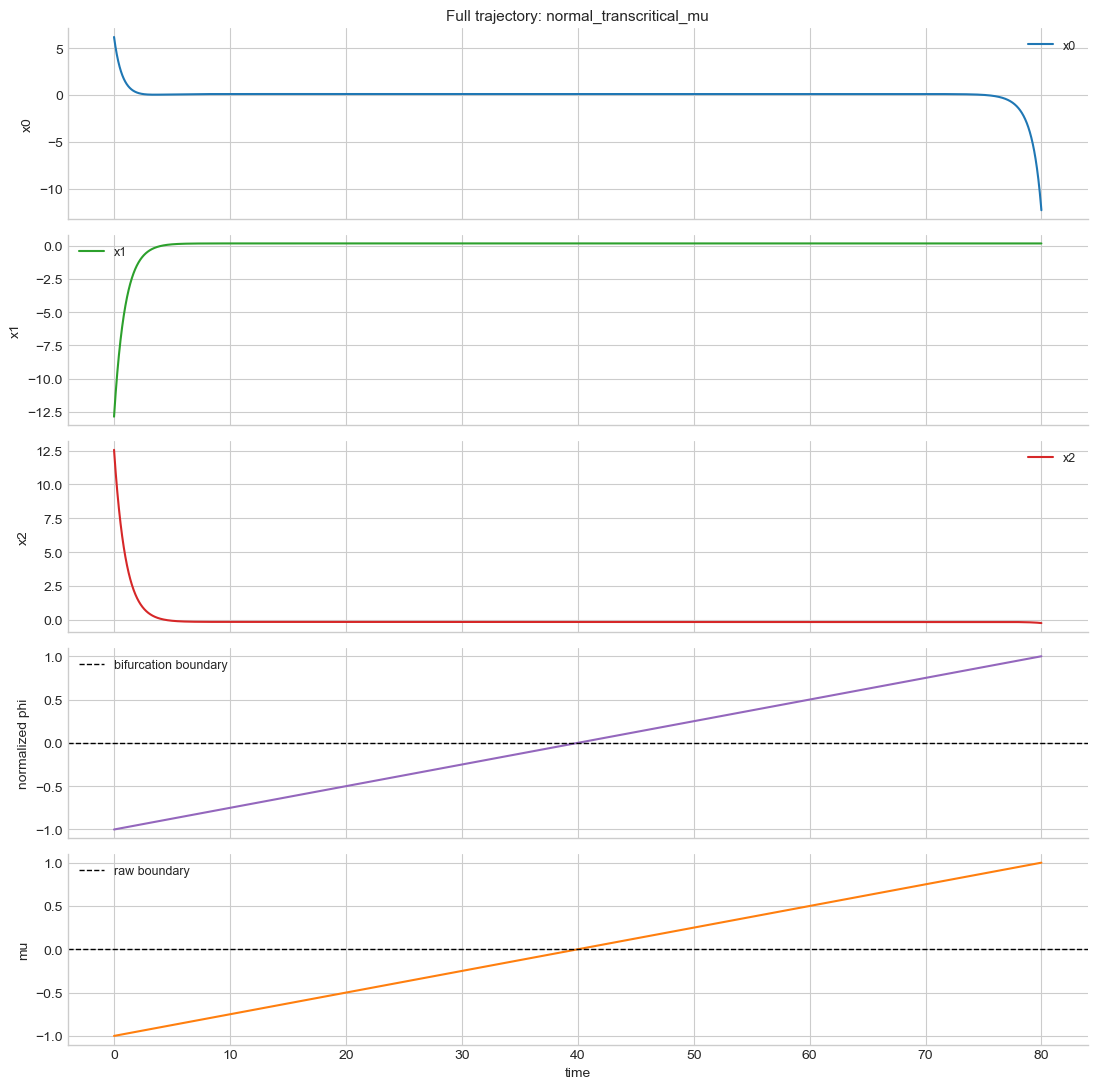

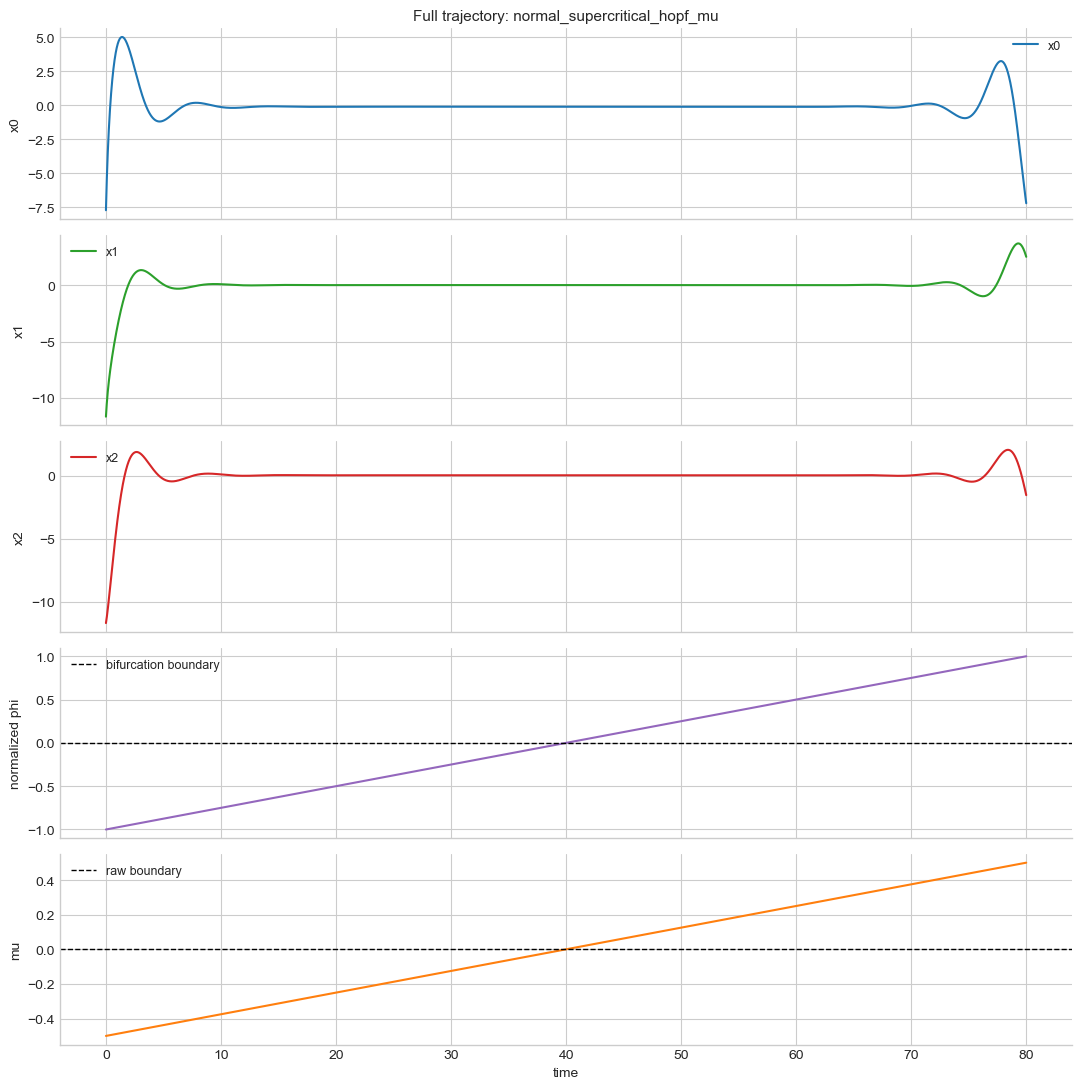

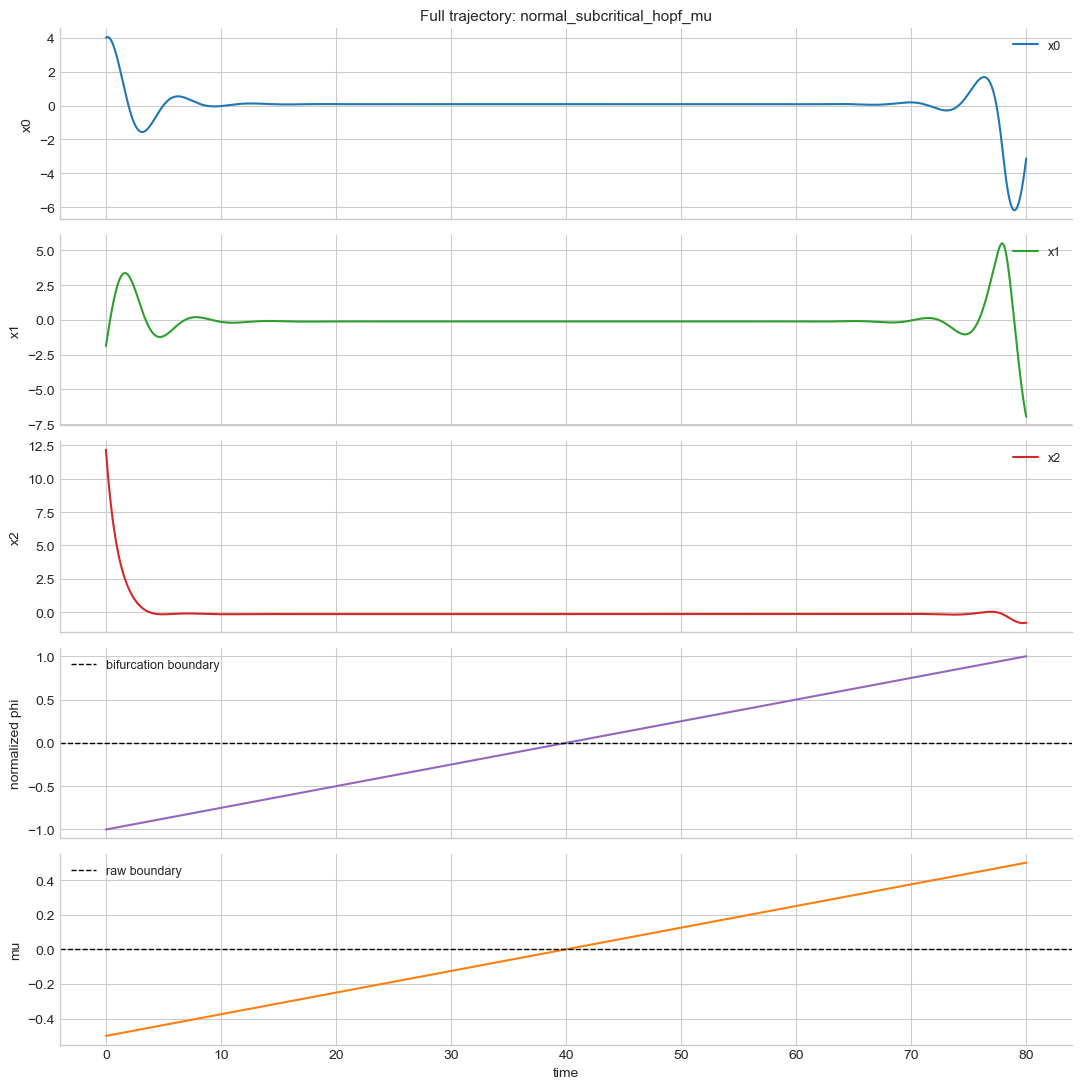

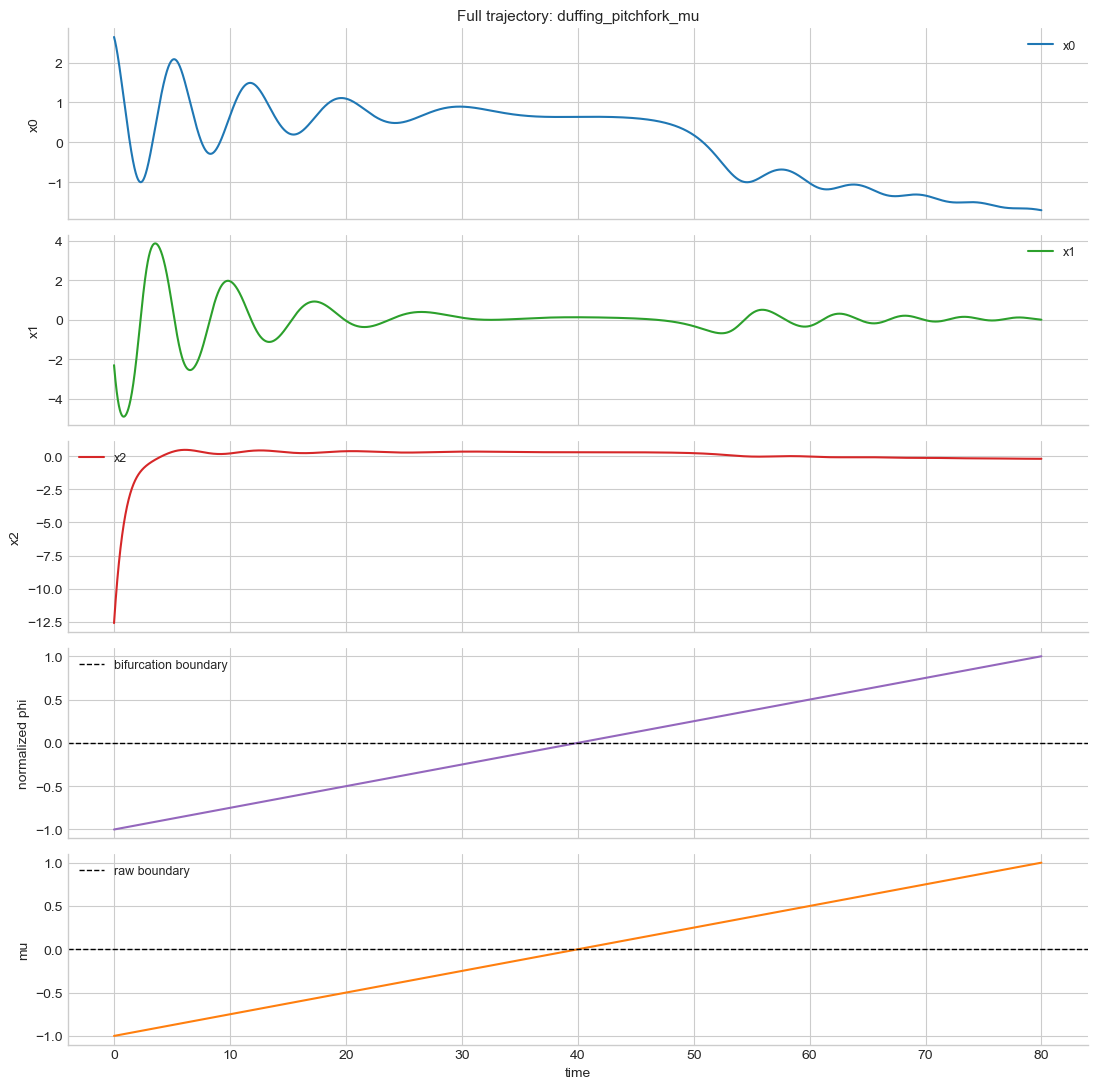

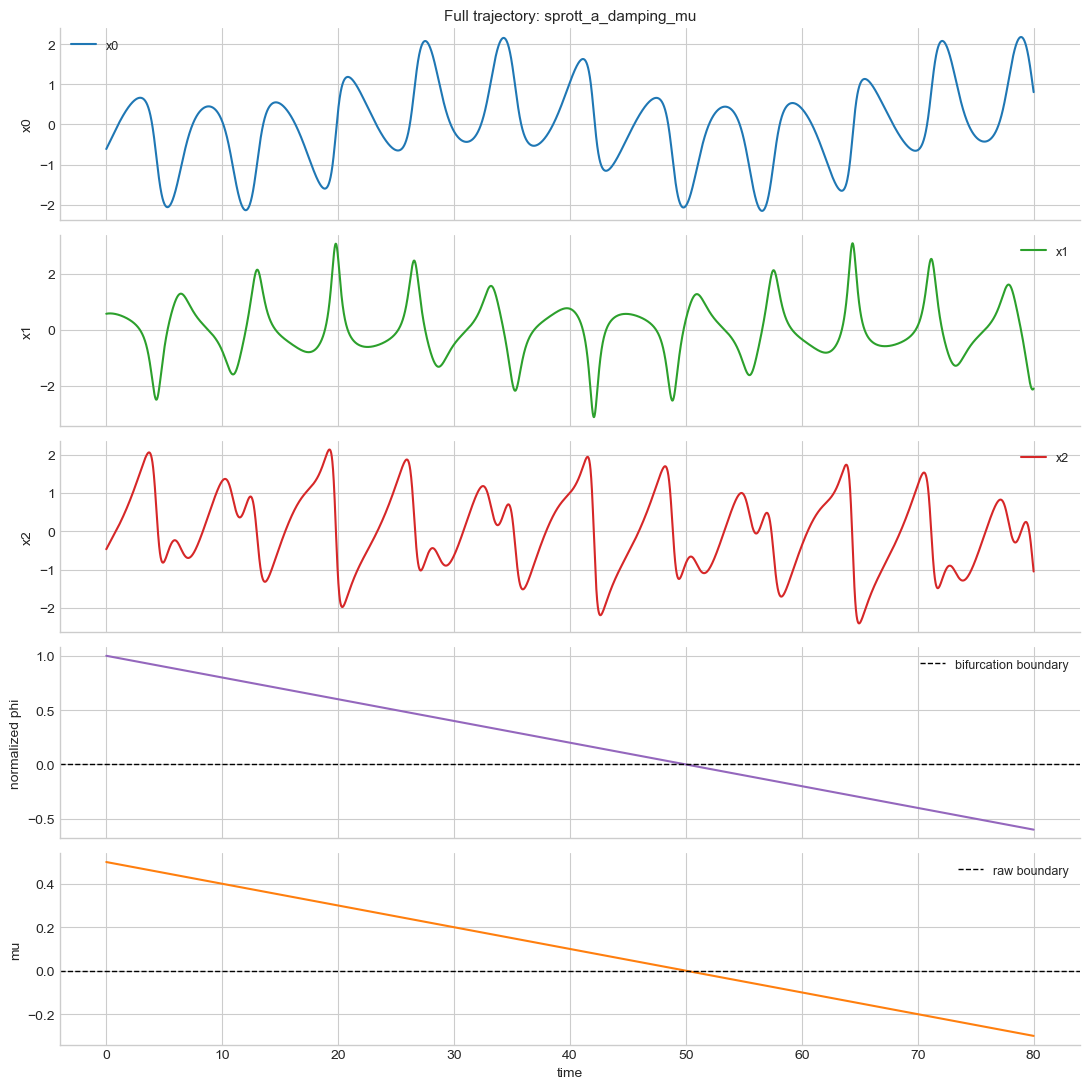

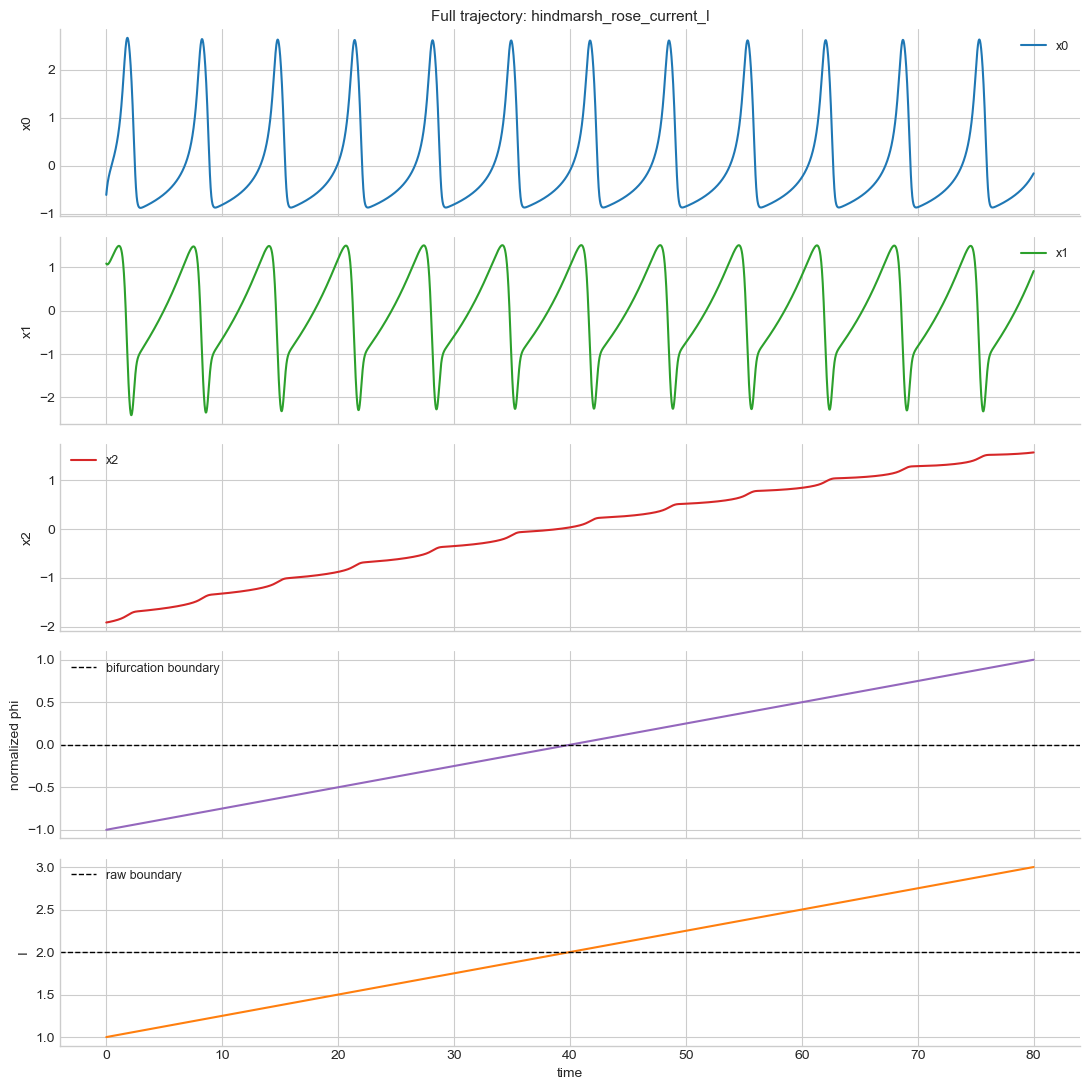

In [10]:
# Change the index to inspect another regime/trajectory.
for index in range(len(arrays["trajectories"])):
    plot_full_trajectory(series_idx=index)

## Plot one training or test window

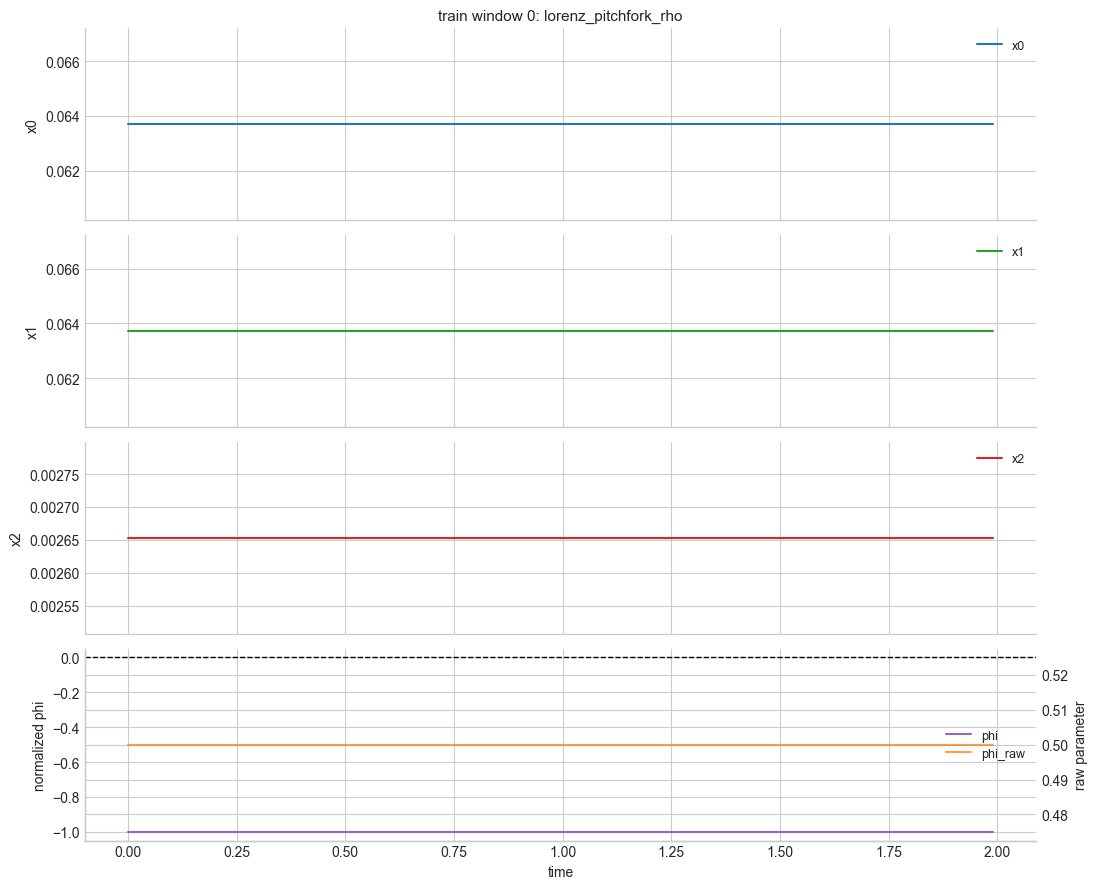

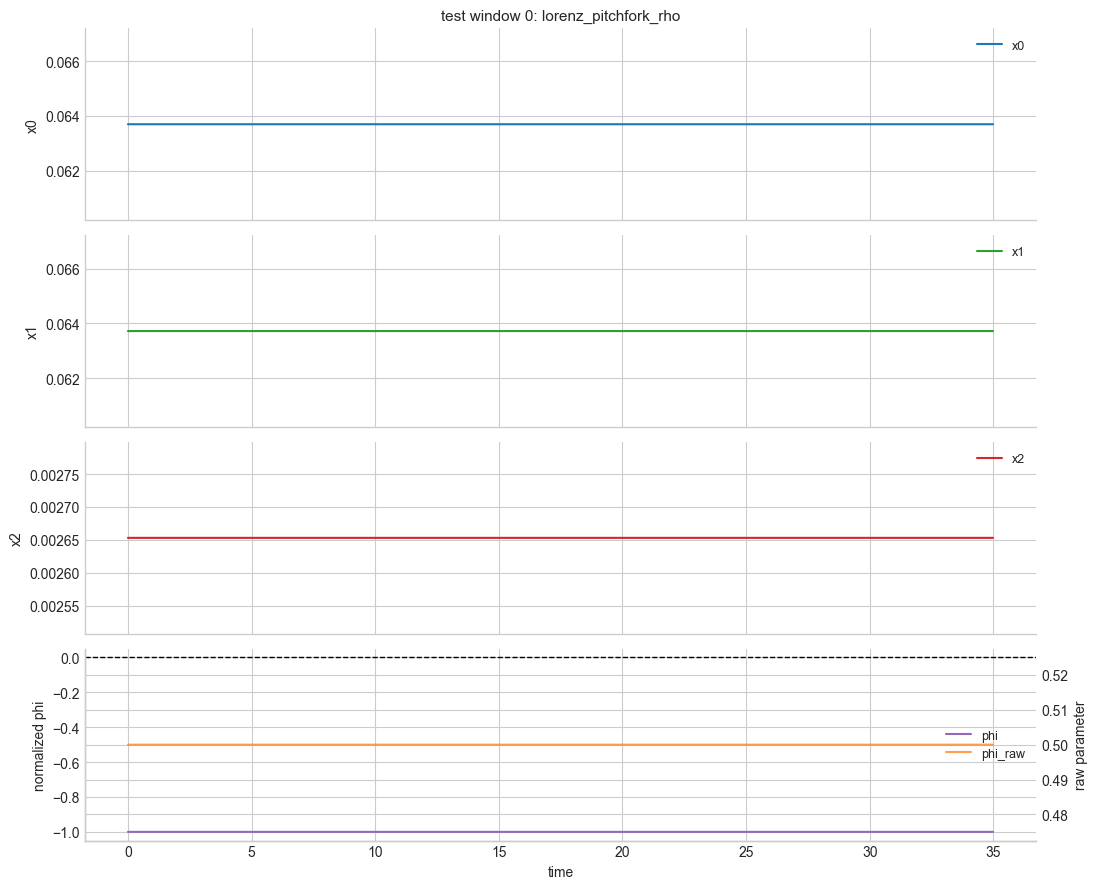

In [7]:
plot_window(window_idx=0, split="train")
plot_window(window_idx=0, split="test");

## Small multiples: one trajectory per regime

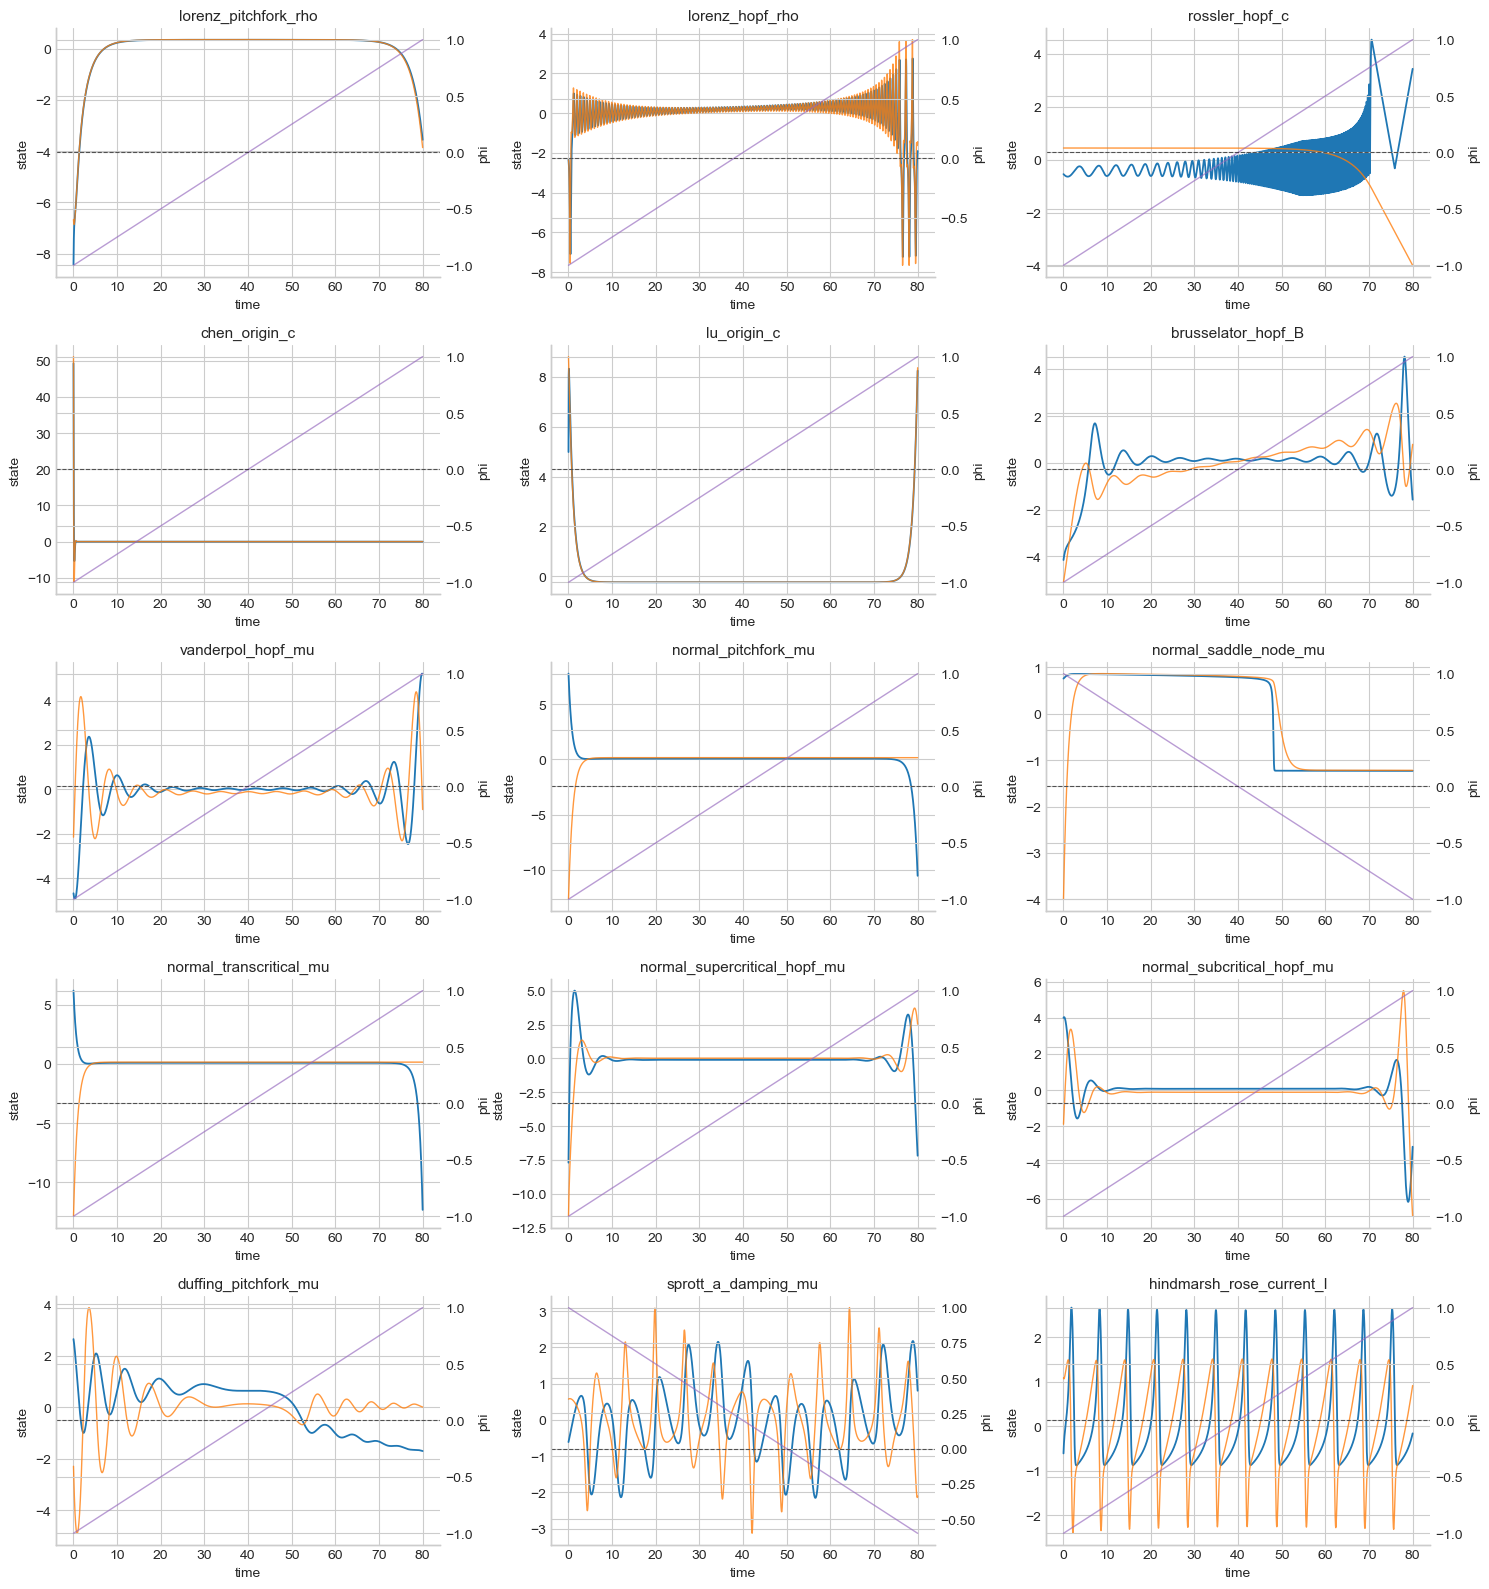

In [11]:
n = len(unique_regimes)
cols = 3
rows = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows, cols, figsize=(15, 3.2 * rows), squeeze=False)

for ax, name in zip(axes.ravel(), unique_regimes):
    idx = indices_for_regime(name)[0]
    x = arrays["trajectories"][idx]
    phi = arrays["trajectory_phi"][idx, :, 0]
    t = time_axis(x.shape[0])
    ax.plot(t, x[:, 0], label="x0", lw=1.3)
    ax.plot(t, x[:, 1], label="x1", lw=1.0, alpha=0.8)
    ax2 = ax.twinx()
    ax2.plot(t, phi, color="tab:purple", lw=1.0, alpha=0.65, label="phi")
    ax2.axhline(0.0, color="black", lw=0.8, ls="--", alpha=0.6)
    ax.set_title(name)
    ax.set_xlabel("time")
    ax.set_ylabel("state")
    ax2.set_ylabel("phi")

for ax in axes.ravel()[n:]:
    ax.set_visible(False)

fig.tight_layout()

## Phase plots

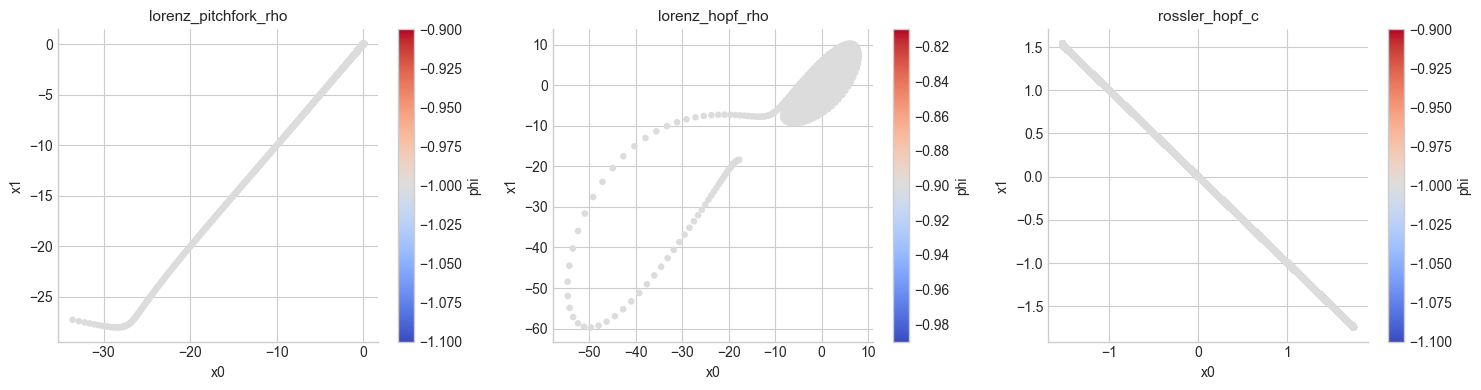

In [9]:
# Colored by normalized phi, so the drift direction is visible.
selected = [0, min(1, len(unique_regimes) - 1), min(2, len(unique_regimes) - 1)]
selected = sorted(set(selected))

fig, axes = plt.subplots(
    1, len(selected), figsize=(5 * len(selected), 4), squeeze=False
)
for ax, regime_idx in zip(axes.ravel(), selected):
    name = unique_regimes[regime_idx]
    idx = indices_for_regime(name)[0]
    x = arrays["trajectories"][idx]
    phi = arrays["trajectory_phi"][idx, :, 0]
    sc = ax.scatter(x[:, 0], x[:, 1], c=phi, s=14, cmap="coolwarm")
    ax.set_title(name)
    ax.set_xlabel("x0")
    ax.set_ylabel("x1")
    fig.colorbar(sc, ax=ax, label="phi")

fig.tight_layout()

## Boundary crossing check

In [10]:
rows = []
for name in unique_regimes:
    idx = indices_for_regime(name)[0]
    phi = arrays["trajectory_phi"][idx, :, 0]
    signs = np.signbit(phi)
    crossing_candidates = np.flatnonzero(signs[:-1] != signs[1:])
    crossing_step = (
        int(crossing_candidates[0] + 1) if crossing_candidates.size else None
    )
    crossing_time = crossing_step * dt if crossing_step is not None else None
    rows.append((name, float(phi[0]), float(phi[-1]), crossing_step, crossing_time))

print(
    f"{'regime':32s} {'phi_start':>10s} {'phi_end':>10s} {'cross_step':>10s} {'cross_time':>10s}"
)
for name, start, end, step, time in rows:
    step_text = "-" if step is None else str(step)
    time_text = "-" if time is None else f"{time:.3f}"
    print(f"{name:32s} {start:10.3f} {end:10.3f} {step_text:>10s} {time_text:>10s}")

regime                            phi_start    phi_end cross_step cross_time
lorenz_pitchfork_rho                 -1.000     -1.000          -          -
lorenz_hopf_rho                      -0.900     -0.900          -          -
rossler_hopf_c                       -1.000     -1.000          -          -
chen_origin_c                        -1.000     -1.000          -          -
lu_origin_c                          -1.000     -1.000          -          -
brusselator_hopf_B                   -1.000     -1.000          -          -
vanderpol_hopf_mu                    -1.000     -1.000          -          -
normal_pitchfork_mu                  -1.000     -1.000          -          -
normal_saddle_node_mu                 1.000      1.000          -          -
normal_transcritical_mu              -1.000     -1.000          -          -
normal_supercritical_hopf_mu         -1.000     -1.000          -          -
normal_subcritical_hopf_mu           -1.000     -1.000          -          -